<a href="https://colab.research.google.com/github/aslafabdulla10-debug/Case_Study_Supervised_Learning/blob/main/Case_Study_Supervised_Learning_Muhammad_Aslaf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.preprocessing import StandardScaler

1.Exploratory Data Analysis (EDA):

Perform a detailed exploratory data analysis to understand the distribution of each feature and its relationship with the target variable(Churn)

In [ ]:
train_df = pd.read_csv("/content/drive/MyDrive/DSAB13/Case Study - Supervised Learning/Dataset/Training_data.csv")
test_df = pd.read_csv("/content/drive/MyDrive/DSAB13/Case Study - Supervised Learning/Dataset/Testing_data.csv")

**ANALYSIS**

In [ ]:
train_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,20.75,700.45,No
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,35.75,961.4,No
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790,No
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,NaN,...,No,Yes,Yes,No,One year,Yes,Bank transfer (automatic),51.25,2151.6,No


In [ ]:
train_df.shape

(5634, 21)

In [ ]:
# Understand column names and data types
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5465 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   int64  
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5465 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [ ]:
# Statistical summary
train_df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,5634,5465,5634.000000,5634,5634,5634.000000,5634,5634,5634,5465,...,5634,5634,5634,5634,5634,5634,5634,5240.000000,5353,5634
unique,5634,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,5040,2
top,9509-MPYOD,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,2744,NaN,2890,3960,NaN,5081,2701,2486,2720,...,2485,2782,2244,2232,3094,3350,1892,NaN,9,4130
mean,NaN,NaN,0.159744,NaN,NaN,32.606851,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.102052,NaN,NaN
std,NaN,NaN,0.366401,NaN,NaN,24.614976,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.056443,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.800000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.650000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,56.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.050000,NaN,NaN


In [ ]:
train_df['Churn'].value_counts()

,count
Churn,
No,4130
Yes,1504


In [ ]:
train_df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.304934
Yes,26.695066


In [ ]:
test_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6080-TCMYC,Male,0,Yes,Yes,40,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,81.20,3292.3,No
1,7285-KLOTR,Female,0,Yes,No,12,Yes,Yes,DSL,Yes,...,Yes,No,Yes,Yes,One year,No,Electronic check,78.85,876.75,No
2,7486-KSRVI,Male,0,No,No,43,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Yes,One year,Yes,Electronic check,100.00,4211.55,Yes
3,9924-JPRMC,Male,0,No,No,72,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,118.20,8547.15,No
4,4439-YRNVD,Female,0,No,No,10,No,No phone service,DSL,No,...,No,Yes,No,No,Month-to-month,No,Electronic check,36.25,374,No


In [ ]:
test_df.shape

(1409, 21)

In [ ]:
train_df.duplicated().sum()

np.int64(0)

Both datasets contain the same columns, including the target variable Churn

customerID is an identifier, not a meaningful customer behavior feature. We will generally exclude it from model training.

TotalCharges is currently an object datatype. We should convert it for EDA, treating blank strings as missing values.

In [ ]:
# errors='coerce' converts invalid values, including blank strings, into NaN.
# This is a temporary cleaning step for analysis; we'll decide the final missing-value treatment during preprocessing.
train_df["TotalCharges"] = pd.to_numeric(train_df["TotalCharges"], errors="coerce")
test_df["TotalCharges"] = pd.to_numeric(test_df["TotalCharges"], errors="coerce")

In [ ]:
# Checks missing values.
train_df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [ ]:
# Checks the peercentage.
(train_df.isnull().sum() / len(train_df)) * 100

,0
customerID,0.000000
gender,2.999645
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,2.999645


Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')
PLOT of Numerical Columns


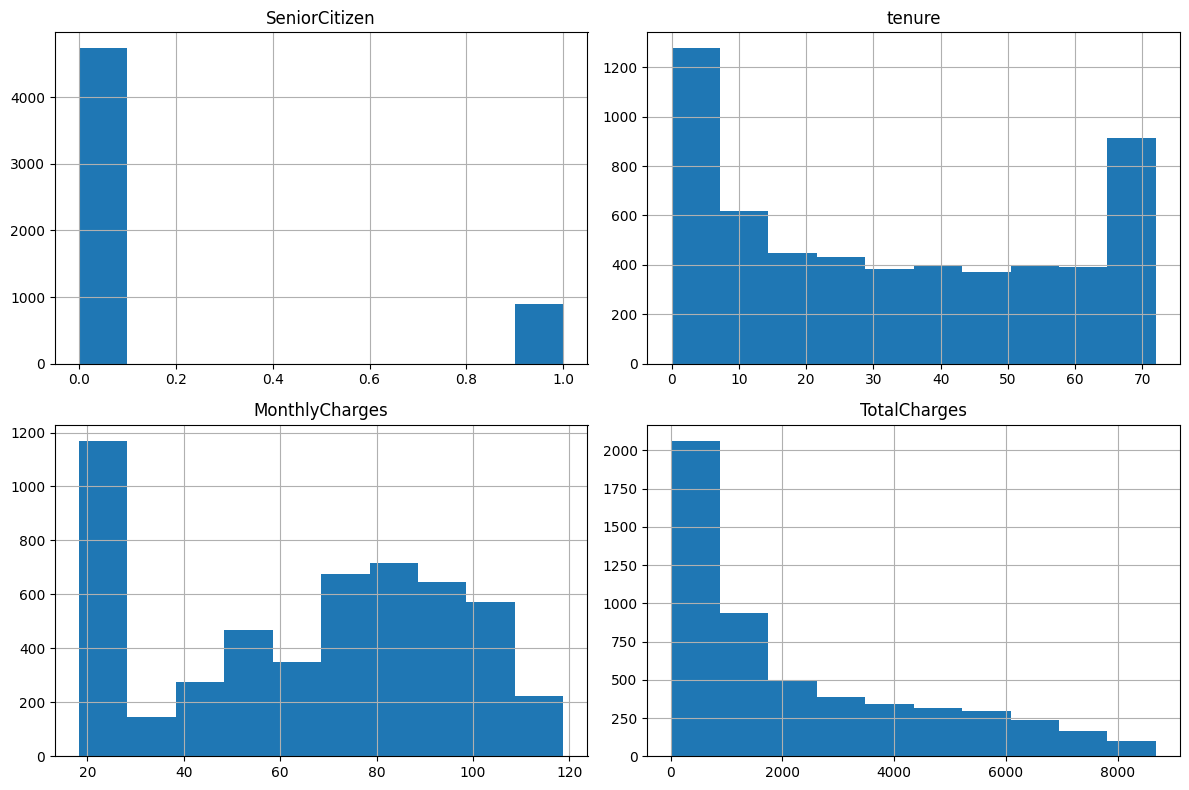

In [ ]:
# Identify numerical columns.
print(train_df.select_dtypes(include=np.number).columns)

# Plot the distributions of the numerical columns.
print("PLOT of Numerical Columns")
train_df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [ ]:
categorical_cols = train_df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(train_df[col].value_counts())


customerID
customerID
9509-MPYOD    1
7746-AWNQW    1
2208-UGTGR    1
4884-LEVMQ    1
6682-VCIXC    1
             ..
5649-RXQTV    1
3908-MKIMJ    1
4277-BWBML    1
9110-HSGTV    1
3402-XRIUO    1
Name: count, Length: 5634, dtype: int64

gender
gender
Male      2744
Female    2721
Name: count, dtype: int64

Partner
Partner
No     2890
Yes    2744
Name: count, dtype: int64

Dependents
Dependents
No     3960
Yes    1674
Name: count, dtype: int64

PhoneService
PhoneService
Yes    5081
No      553
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  2701
Yes                 2380
No phone service     553
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    2486
DSL            1945
No             1203
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     2720
Yes                    1574
No internet service    1171
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     2459
Yes                    1972


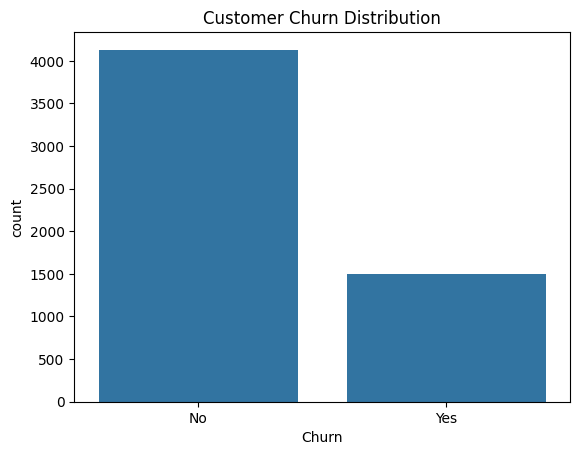

In [ ]:
# Identify class imbalance between customers who churned and those who stayed.
sb.countplot(data=train_df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

**Analyze numerical features against Churn**

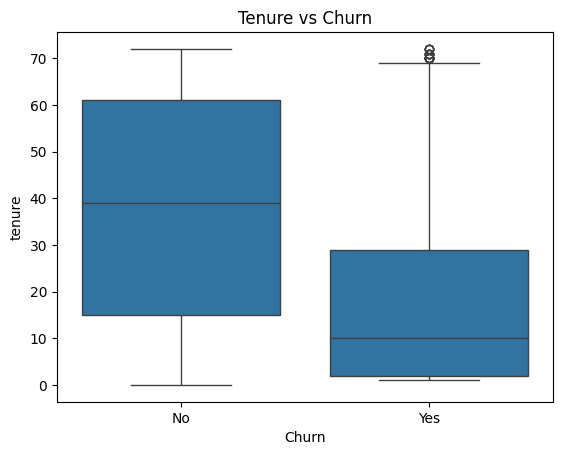

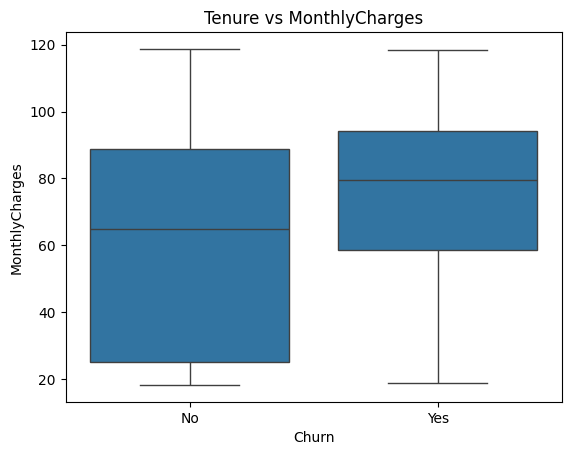

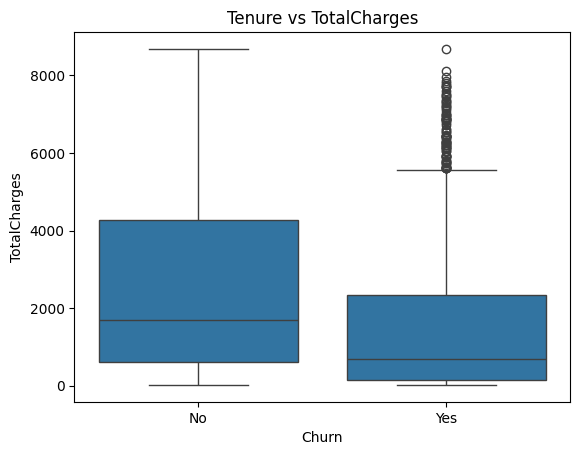

In [ ]:
sb.boxplot(data=train_df, x='Churn', y='tenure')
plt.title('Tenure vs Churn')
plt.show()
print('\n')
sb.boxplot(data=train_df, x='Churn', y='MonthlyCharges')
plt.title('Tenure vs MonthlyCharges')
plt.show()
print('\n')
sb.boxplot(data=train_df, x='Churn', y='TotalCharges')
plt.title('Tenure vs TotalCharges')
plt.show()

Analyze categorical features against Churn

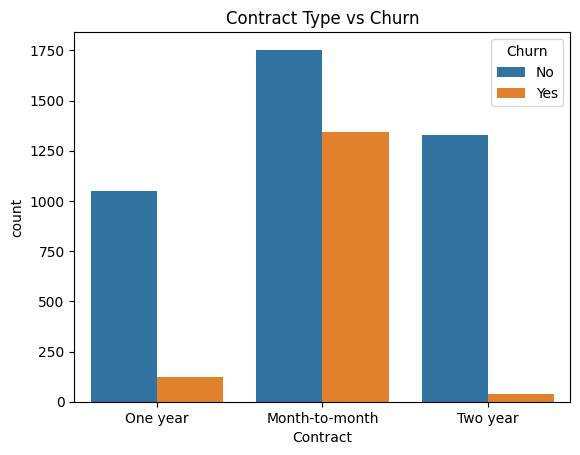

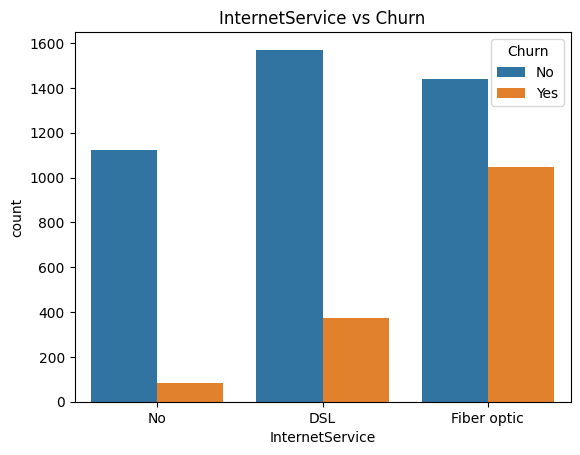

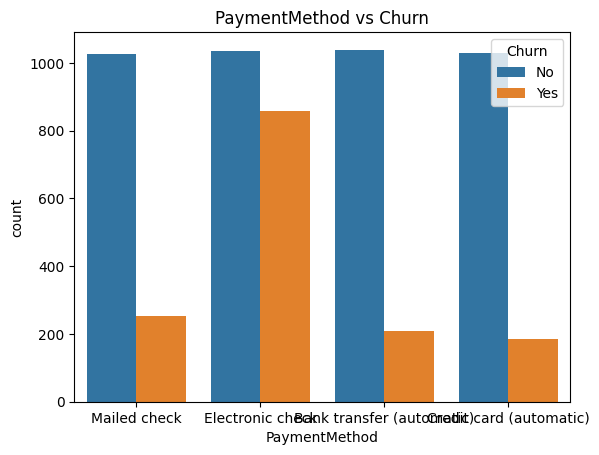

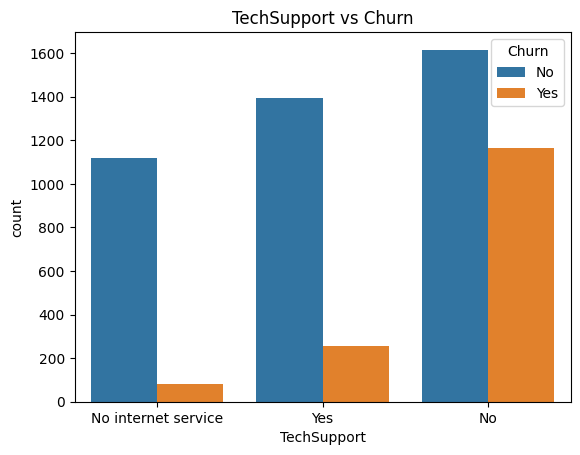

In [ ]:
sb.countplot(data=train_df, x='Contract', hue='Churn')
plt.title('Contract Type vs Churn')
plt.show()
print('\n')
sb.countplot(data=train_df, x='InternetService', hue='Churn')
plt.title('InternetService vs Churn')
plt.show()
print('\n')
sb.countplot(data=train_df, x='PaymentMethod', hue='Churn')
plt.title('PaymentMethod vs Churn')
plt.show()
print('\n')
sb.countplot(data=train_df, x='TechSupport', hue='Churn')
plt.title('TechSupport vs Churn')
plt.show()

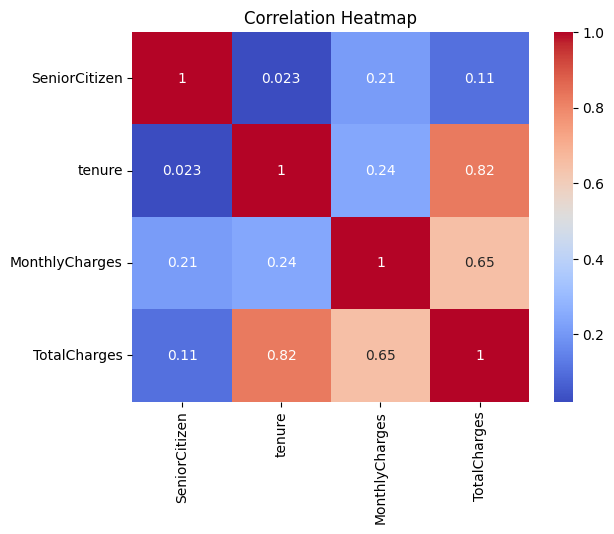

In [ ]:
# Correlation analysis
numeric_df = train_df.select_dtypes(include=np.number)

sb.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

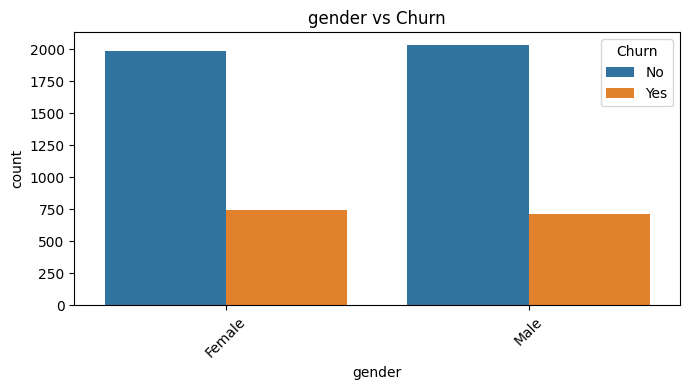

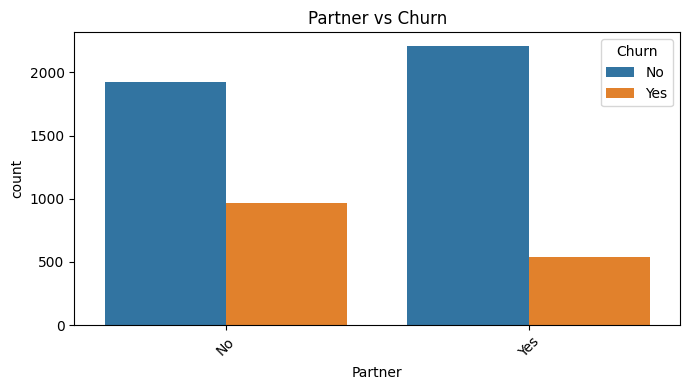

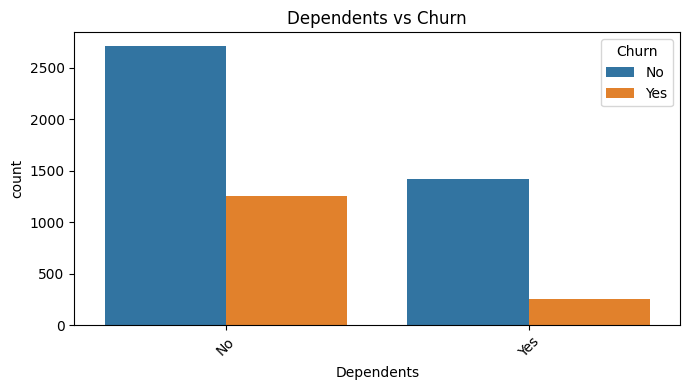

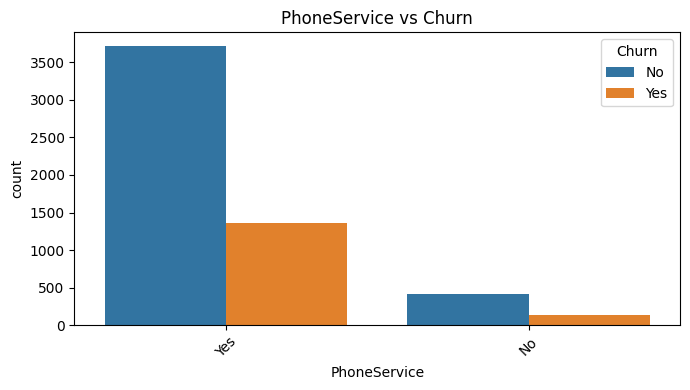

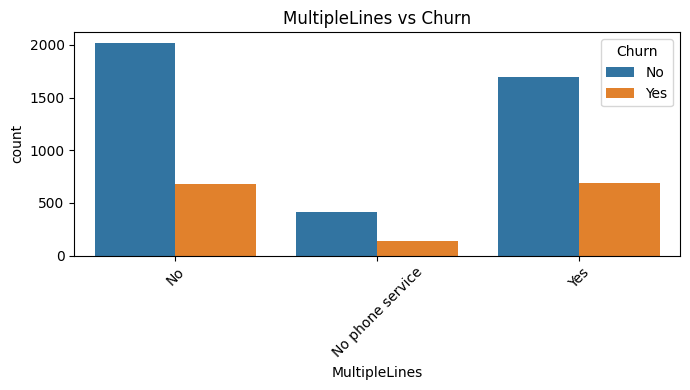

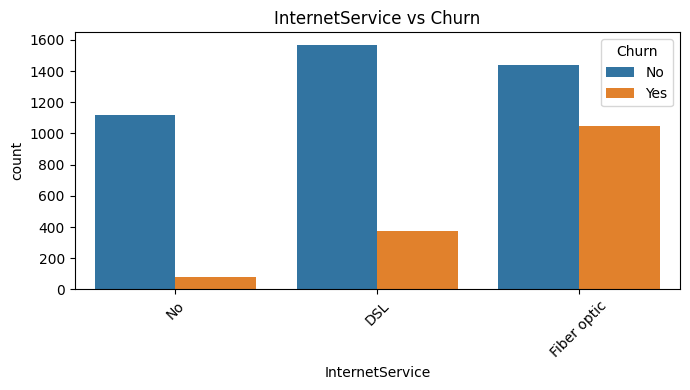

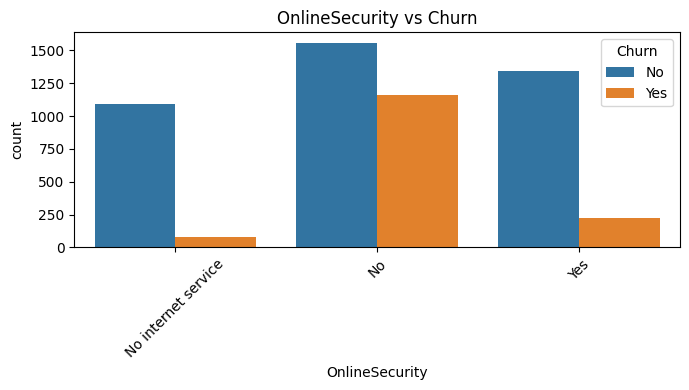

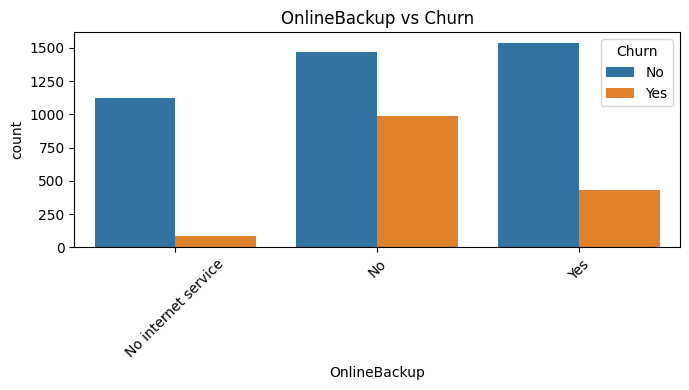

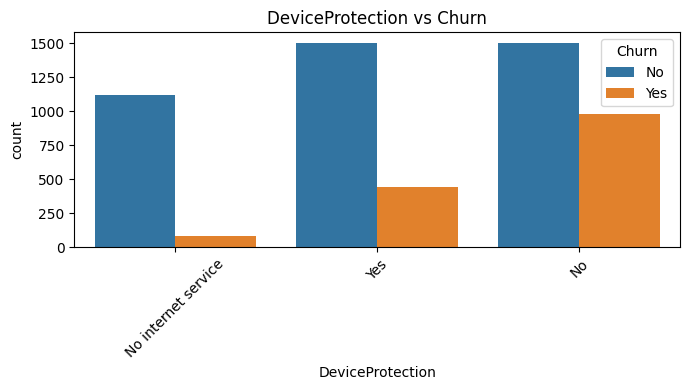

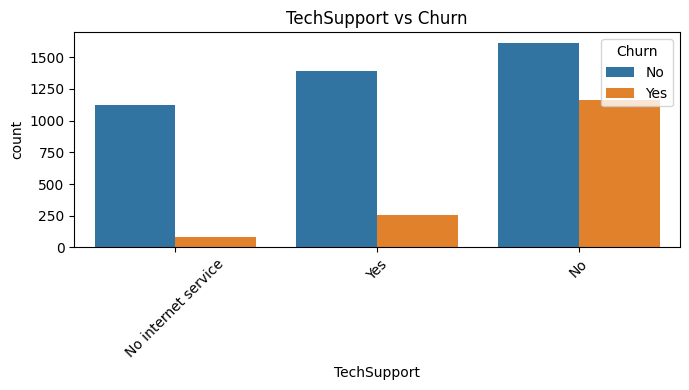

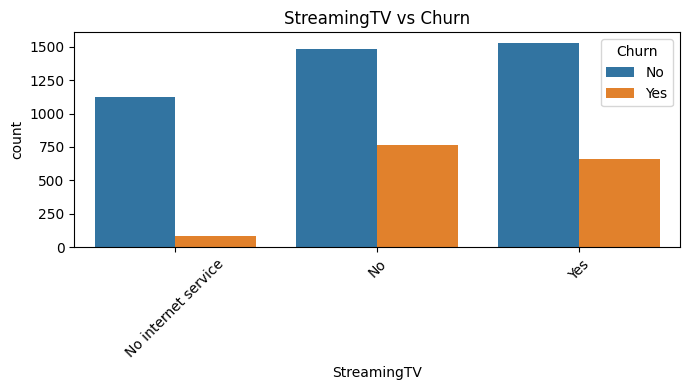

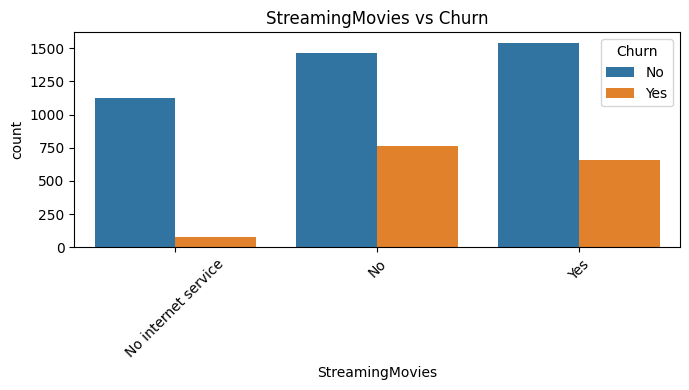

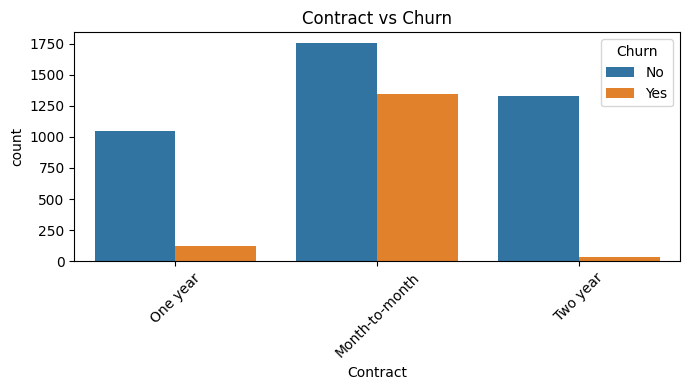

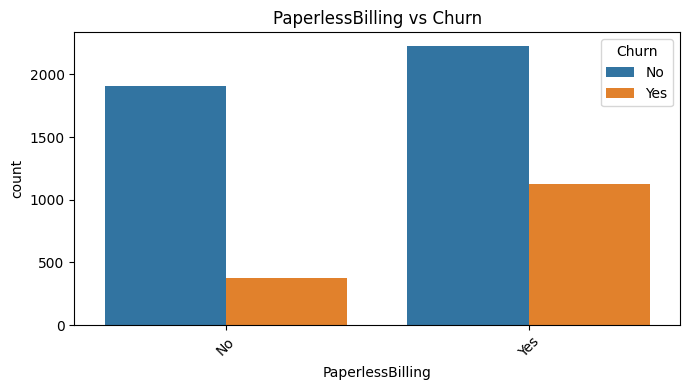

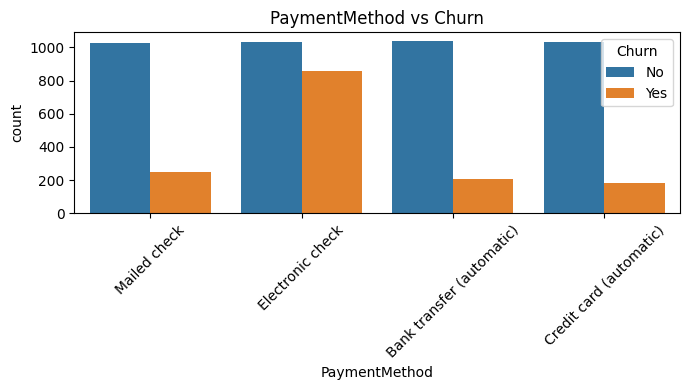

In [ ]:
# Compare all the categorical features with churn using loop.
categorical_cols = [
    col for col in train_df.select_dtypes(include='object').columns
    if col not in ['customerID', 'Churn']
]

for col in categorical_cols:
    plt.figure(figsize=(7, 4))

    sb.countplot(data=train_df, x=col, hue='Churn')

    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

2. Data Preprocessing

In [ ]:
train_df.isnull()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5630,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5631,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5632,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
train_df.isnull().sum()

,0
customerID,0
gender,169
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,169


In [ ]:
# Replace the missing values using filna
# for categorical columns - use mode
# for numerical columns - use median

# Categorical columns
train_df['gender'] = train_df['gender'].fillna(train_df['gender'].mode()[0])

train_df['OnlineSecurity'] = train_df['OnlineSecurity'].fillna(
    train_df['OnlineSecurity'].mode()[0])

# Numerical column
train_df['MonthlyCharges'] = train_df['MonthlyCharges'].fillna(
    train_df['MonthlyCharges'].median())

In [ ]:
# customers with zero tenure may legitimately have zero total charges.
# check whether TotalCharges missing values are associated with customers having zero tenure.
train_df.loc[
    (train_df['TotalCharges'].isnull()) &
    (train_df['tenure']==0),
    ["tenure","TotalCharges"]
]

,tenure,TotalCharges
1120,0,NaN
1284,0,NaN
1347,0,NaN
3116,0,NaN
3575,0,NaN
4163,0,NaN
4323,0,NaN
4391,0,NaN
5212,0,NaN


In [ ]:
# change the value of Totalcharges = Nan to Zero if the tenure = 0
# if tenure not zero and TotalCharges is Nan, use median to replace.
# Customers with zero tenure
train_df.loc[
    (train_df['TotalCharges'].isnull()) & (train_df['tenure'] == 0),
    'TotalCharges'
] = 0

# Customers with non-zero tenure
train_df['TotalCharges'] = train_df['TotalCharges'].fillna(
    train_df['TotalCharges'].median()
)

Categorical Encoding

Label Encoding: Assigns numerical values to categories.



One-Hot Encoding: Creates separate binary columns for each category.

In [ ]:
# Identify categorical columns.
categorical_cols = train_df.select_dtypes(include='object').columns.tolist()

# Exclude
# customerID: Unique identifier; it doesn't provide useful predictive information.
# Churn: This is our target variable, which we want to predict. It must not be included as an input feature.

categorical_cols.remove('customerID')
categorical_cols.remove('Churn')

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


**One-Hot Encoding**

use get_dummies() to understand how One-Hot Encoding works

Converts each categorical feature into separate binary columns.

1 means the category is present.

0 means the category is absent.

Keeps numerical columns unchanged.

```
# This is formatted as code
```



In [ ]:
train_encoded = pd.get_dummies(
    train_df,
    columns=categorical_cols,
    dtype=int
)

print(train_encoded.shape)
print("\  n","\n")
print(train_encoded.head())

(5634, 47)
\  n 

   customerID  SeniorCitizen  tenure  MonthlyCharges  TotalCharges Churn  \
0  9509-MPYOD              0      35           20.75        700.45    No   
1  7746-AWNQW              0      28           35.75        961.40    No   
2  2208-UGTGR              0      56           98.60       5581.05    No   
3  4884-LEVMQ              0      39           20.45        790.00    No   
4  6682-VCIXC              0      43           51.25       2151.60    No   

   gender_Female  gender_Male  Partner_No  Partner_Yes  ...  \
0              1            0           1            0  ...   
1              1            0           1            0  ...   
2              0            1           1            0  ...   
3              0            1           0            1  ...   
4              1            0           0            1  ...   

   StreamingMovies_Yes  Contract_Month-to-month  Contract_One year  \
0                    0                        0                  1   
1     

<>:8: SyntaxWarning: invalid escape sequence '\ '
<>:8: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_1585/710357109.py:8: SyntaxWarning: invalid escape sequence '\ '
  print("\  n","\n")


In [ ]:
# scale the numerical columns in a separate DataFrame.
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()

train_scaled = train_df.copy()

train_scaled[numerical_cols] = scaler.fit_transform(
    train_scaled[numerical_cols]
)

train_scaled[numerical_cols].head()

,tenure,MonthlyCharges,TotalCharges
0,0.097232,-1.541793,-0.692296
1,-0.187173,-1.024876,-0.574631
2,0.950447,1.141008,1.508416
3,0.259749,-1.552131,-0.651917
4,0.422266,-0.490728,-0.037958


In [ ]:
# Outlier Handling
# IQR

numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in numerical_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train_df[
        (train_df[col] < lower) | (train_df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outliers')

tenure: 0 outliers
MonthlyCharges: 0 outliers
TotalCharges: 23 outliers


In [ ]:
Q1 = train_df['TotalCharges'].quantile(0.25)
Q3 = train_df['TotalCharges'].quantile(0.75)
IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

outliers = train_df[train_df['TotalCharges'] > upper]

outliers[['tenure', 'MonthlyCharges', 'TotalCharges']].head(10)

,tenure,MonthlyCharges,TotalCharges
93,72,115.15,8349.45
111,72,114.90,8496.70
269,72,115.80,8476.50
724,72,114.85,8317.95
901,72,115.80,8332.15
1666,72,116.05,8404.90
1865,72,115.50,8425.15
1959,72,117.50,8670.10
2085,72,117.80,8684.80
2767,72,114.05,8468.20


From the above data:

Decision: Retain all 23 outliers.

Reason:The values are within a plausible business range.
They are consistent with long customer tenure and monthly charges.
Removing them would result in losing valid customer information.
The IQR method identified 23 potential outliers in TotalCharges. Upon inspection, these observations corresponded to customers with long tenure and higher monthly charges. Since the values were plausible and represented genuine customer behaviour, no outlier removal or transformation was performed.

3. Feature Engineering

In [34]:
def feature_engineering(df):
    df = df.copy()

    # Ensure column names are referenced with correct lowercase 'tenure'
    # Customer lifetime value approximation
    df["CustomerLifetimeValue"] = df["tenure"] * df["MonthlyCharges"]

    # Average monthly charges based on tenure
    df["AverageMonthlyCharges"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)

    # Customer tenure groups
    df["TenureGroup"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=["New", "Short", "Medium", "Long"]
    )

    return df

In [36]:
train = feature_engineering(train_df)
test = feature_engineering(test_df)
train.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerLifetimeValue,AverageMonthlyCharges,TenureGroup
0,9509-MPYOD,Female,0,No,No,35,Yes,No,No,No internet service,...,No internet service,One year,No,Mailed check,20.75,700.45,No,726.25,20.012857,Medium
1,7746-AWNQW,Female,0,No,No,28,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Mailed check,35.75,961.40,No,1001.00,34.335714,Medium
2,2208-UGTGR,Male,0,No,No,56,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,No,Electronic check,98.60,5581.05,No,5521.60,99.661607,Long
3,4884-LEVMQ,Male,0,Yes,No,39,Yes,No,No,No internet service,...,No internet service,Two year,Yes,Bank transfer (automatic),20.45,790.00,No,797.55,20.256410,Medium
4,6682-VCIXC,Female,0,Yes,Yes,43,No,No phone service,DSL,No,...,No,One year,Yes,Bank transfer (automatic),51.25,2151.60,No,2203.75,50.037209,Medium


In [37]:
# Remove CustomerID because it is only an identifier
train = train.drop(
    columns=["CustomerID"],
    errors="ignore"
)
test = test.drop(
    columns=["CustomerID"],
    errors="ignore"
)

In [38]:
# Separate input features and target
X = train.drop(columns=["Churn"])
y = train["Churn"].map({
    "Yes": 1,
    "No": 0
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5634, 23)
Target shape: (5634,)


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)

X_train: (4507, 23)
X_val: (1127, 23)


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'CustomerLifetimeValue', 'AverageMonthlyCharges']
Categorical features: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [41]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

4. Model Development

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [47]:
trained_models = {}
for name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
results = []
for name, model in trained_models.items():
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )
    roc_auc = roc_auc_score(
        y_val,
        y_prob
    )
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.771961,0.552381,0.770764,0.643551,0.847542
1,Random Forest,0.800355,0.669643,0.498339,0.571429,0.842291
2,Gradient Boosting,0.807453,0.672131,0.544850,0.601835,0.850050


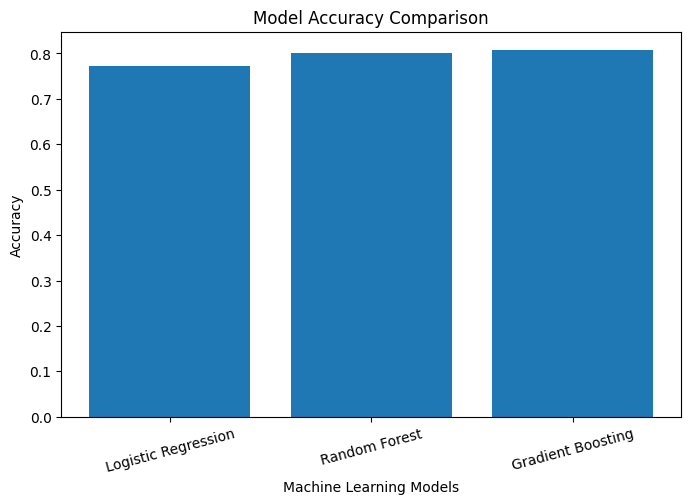

In [51]:
# Plot the accuracy of the three models
plt.figure(figsize=(8, 5))
plt.bar(results_df['Model'], results_df['Accuracy'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=15)
plt.show()

In [52]:
for name, model in trained_models.items():
    print("\nModel:", name)
    y_pred = model.predict(X_val)
    print(
        classification_report(
            y_val,
            y_pred,
            target_names=["No Churn", "Churn"]
        )
    )


Model: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83       826
       Churn       0.55      0.77      0.64       301

    accuracy                           0.77      1127
   macro avg       0.73      0.77      0.74      1127
weighted avg       0.81      0.77      0.78      1127


Model: Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87       826
       Churn       0.67      0.50      0.57       301

    accuracy                           0.80      1127
   macro avg       0.75      0.70      0.72      1127
weighted avg       0.79      0.80      0.79      1127


Model: Gradient Boosting
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87       826
       Churn       0.67      0.54      0.60       301

    accuracy                           0.81      1127
   macro avg       0.76      0.72      0.74      112

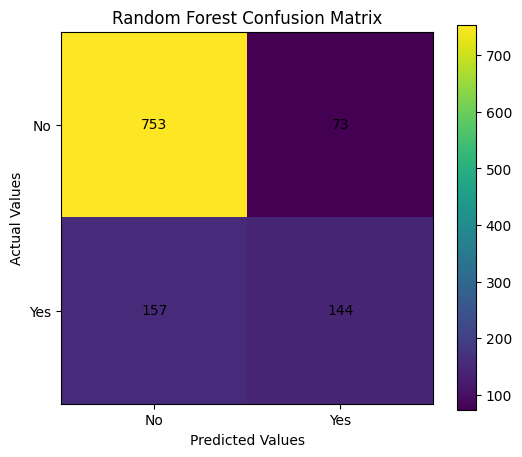

In [54]:
# Select the Random Forest model for confusion matrix analysis
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

# Train the Random Forest model
rf_pipeline.fit(X_train, y_train)

# Predict the validation data
rf_predictions = rf_pipeline.predict(X_val)

# Generate the confusion matrix
cm = confusion_matrix(y_val, rf_predictions, labels=[0, 1])

# Display the confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.xticks([0, 1], ['No', 'Yes'])
plt.yticks([0, 1], ['No', 'Yes'])

# Display the values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

In [55]:
# Get the trained Random Forest model
rf_model = rf_pipeline.named_steps['model']

# Get the transformed feature names after preprocessing
feature_names = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get the importance values
importance = rf_model.feature_importances_

# Create a DataFrame containing feature names and importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort features from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the top 15 important features
feature_importance.head(15)

,Feature,Importance
4,num__CustomerLifetimeValue,0.063942
3,num__TotalCharges,0.061373
1,num__tenure,0.058416
2,num__MonthlyCharges,0.057333
5,num__AverageMonthlyCharges,0.056171
4545,cat__Contract_Month-to-month,0.032168
4556,cat__TenureGroup_New,0.021892
4536,cat__TechSupport_No,0.020365
4552,cat__PaymentMethod_Electronic check,0.018471
4525,cat__InternetService_Fiber optic,0.016834


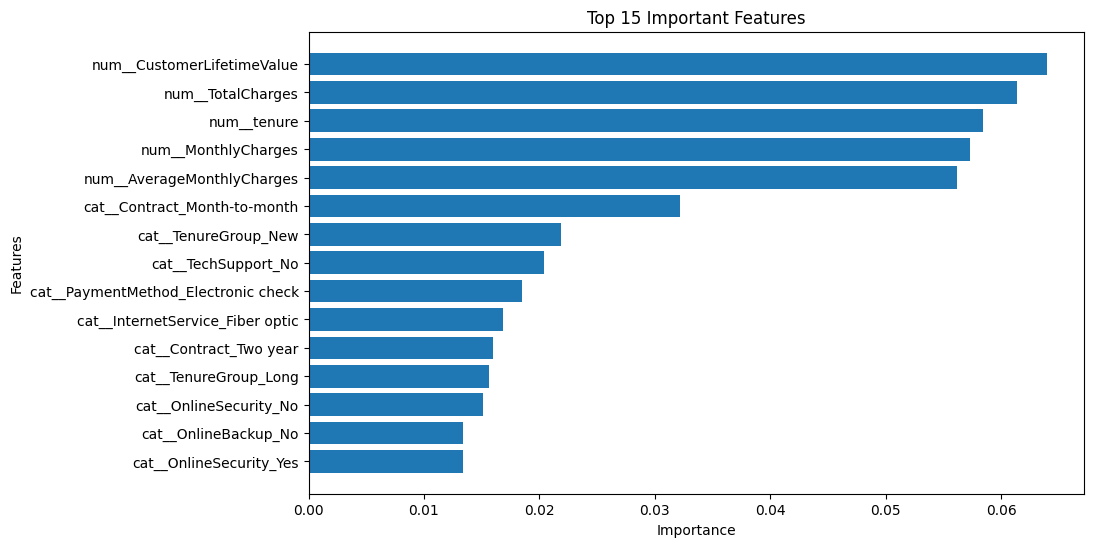

In [56]:
# Select the top 15 important features
top_features = feature_importance.head(15)

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.title('Top 15 Important Features')
plt.xlabel('Importance')
plt.ylabel('Features')

# Display the most important feature at the top
plt.gca().invert_yaxis()
plt.show()

5. Model Fine-Tuning

In [57]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Create a pipeline containing preprocessing and Random Forest
rf_tuning_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

In [60]:
# Define different Random Forest settings to test
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

In [63]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges',
                                                                          'CustomerLifetimeValue',
                                                                          'AverageMonthlyCharges']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(stra...
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod',
                                                                          'TenureGroup'])])),
                                       ('model',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [None, 10, 20],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='roc_auc', verbose=1)

In [65]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}


In [66]:
print("Best Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Best Cross-Validation ROC-AUC:
0.8461302502902458


In [67]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_val)
y_prob_tuned = best_model.predict_proba(X_val)[:, 1]
print(
    classification_report(
        y_val,
        y_pred_tuned,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.81      0.93      0.87       826
       Churn       0.70      0.42      0.52       301

    accuracy                           0.80      1127
   macro avg       0.76      0.67      0.70      1127
weighted avg       0.78      0.80      0.78      1127



In [68]:
print(
    "Tuned Accuracy:",
    accuracy_score(y_val, y_pred_tuned)
)
print(
    "Tuned ROC-AUC:",
    roc_auc_score(y_val, y_prob_tuned)
)

Tuned Accuracy: 0.7959183673469388
Tuned ROC-AUC: 0.850144393587155


In [69]:
before_tuning = trained_models["Random Forest"]
before_pred = before_tuning.predict(X_val)
before_prob = before_tuning.predict_proba(X_val)[:, 1]
comparison = pd.DataFrame({
    "Model": [
        "Random Forest Before Tuning",
        "Random Forest After Tuning"
    ],
    "Accuracy": [
        accuracy_score(y_val, before_pred),
        accuracy_score(y_val, y_pred_tuned)
    ],
    "F1 Score": [
        f1_score(y_val, before_pred),
        f1_score(y_val, y_pred_tuned)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, before_prob),
        roc_auc_score(y_val, y_prob_tuned)
    ]
})
comparison

,Model,Accuracy,F1 Score,ROC-AUC
0,Random Forest Before Tuning,0.800355,0.571429,0.842291
1,Random Forest After Tuning,0.795918,0.520833,0.850144


In [70]:
final_model = grid_search.best_estimator_
final_model.fit(X, y)
print("Final model trained successfully")

Final model trained successfully


In [71]:
if "Churn" in test.columns:
    X_test = test.drop(columns=["Churn"])
    y_test = test["Churn"].map({
        "Yes": 1,
        "No": 0
    })
else:
    X_test = test.copy()

In [72]:
test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]
print("Predictions completed")

Predictions completed


In [73]:
if "Churn" in test.columns:
    print(
        classification_report(
            y_test,
            test_predictions,
            target_names=["No Churn", "Churn"]
        )
    )
    print(
        "Testing Accuracy:",
        accuracy_score(y_test, test_predictions)
    )
    print(
        "Testing ROC-AUC:",
        roc_auc_score(y_test, test_probabilities)
    )

              precision    recall  f1-score   support

    No Churn       0.82      0.94      0.88      1044
       Churn       0.70      0.41      0.51       365

    accuracy                           0.80      1409
   macro avg       0.76      0.67      0.69      1409
weighted avg       0.79      0.80      0.78      1409

Testing Accuracy: 0.801277501774308
Testing ROC-AUC: 0.8262740775730857


In [74]:
final_results = pd.DataFrame({
    "CustomerID": test["CustomerID"]
        if "CustomerID" in test.columns
        else np.arange(len(test)),
    "Actual_Churn": test["Churn"]
        if "Churn" in test.columns
        else "Not Available",
    "Predicted_Churn": np.where(
        test_predictions == 1,
        "Yes",
        "No"
    ),
    "Churn_Probability": test_probabilities
})
final_results.head()

,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,No,No,0.381905
1,1,No,No,0.257784
2,2,Yes,No,0.297502
3,3,No,No,0.132845
4,4,No,No,0.304321


In [75]:
final_results.to_csv(
    "Customer_Churn_Predictions.csv",
    index=False
)
print("Prediction file saved successfully")

Prediction file saved successfully


**Conclusion:**

The Customer Churn Prediction project aims to identify customers who are likely to leave a telecom company.
- EDA was performed to understand the dataset and identify patterns.
- Missing values and categorical features were handled during preprocessing.
- Feature engineering was performed by creating CLV and Tenure_Contract.
- Three machine learning models were trained and compared.
- Model performance was evaluated using accuracy, precision, recall and F1 score.
- Random Forest was selected for hyperparameter tuning using GridSearchCV.
- Important features were identified to understand the factors influencing customer churn.


**Business Recommendations:**
- Identify customers who have a high probability of leaving.
- Provide special offers to customers with short tenure.
- Improve customer support services.
- Encourage customers to choose long-term contracts.
- Investigate payment methods and service-related issues associated with churn.